In [ ]:
import shutil
import psutil

total, used, free = shutil.disk_usage("/content")
ram = psutil.virtual_memory()

print(f"Free disk space: {free / (1024**3):.2f} GB")
print(f"Total RAM: {ram.total / (1024**3):.2f} GB")
print(f"Available RAM: {ram.available / (1024**3):.2f} GB")

Free disk space: 87.21 GB
Total RAM: 12.67 GB
Available RAM: 11.45 GB


In [ ]:
!pip install -q pandas dask[complete] psutil matplotlib pyarrow

In [ ]:
import os
import time
import threading
import multiprocessing as mp

import psutil
import pandas as pd
import matplotlib.pyplot as plt
import dask
import dask.dataframe as dd

DATA_DIR = "/content/big_data"
CSV_PATH = os.path.join(DATA_DIR, "amazon_ratings.csv")
COLUMN_NAMES = ["item_id", "user_id", "rating", "timestamp"]

if not os.path.isfile(CSV_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {CSV_PATH}\n"
        "Upload the CSV file to this location before continuing."
    )

file_size_gb = os.path.getsize(CSV_PATH) / (1024**3)
ram = psutil.virtual_memory()
disk = psutil.disk_usage("/content")

print(f"Dataset size: {file_size_gb:.2f} GB")
print(f"Available RAM: {ram.available / (1024**3):.2f} GB")
print(f"Free disk space: {disk.free / (1024**3):.2f} GB")

if file_size_gb <= 5:
    print("Warning: The dataset is not larger than 5 GB.")
else:
    print("Dataset meets the 5 GB requirement.")

Dataset size: 9.06 GB
Available RAM: 10.80 GB
Free disk space: 78.14 GB
Dataset meets the 5 GB requirement.


In [ ]:
df_sample = pd.read_csv(
    CSV_PATH,
    header=None,
    names=COLUMN_NAMES,
    nrows=5
)

display(df_sample)

print("Columns:", df_sample.columns.tolist())
print("Sample shape:", df_sample.shape)

,item_id,user_id,rating,timestamp
0,B00ZGTMHVU,A1HGH7NF01K3W7,5.0,1451001600
1,B013CG1EVC,A3GDQGSD4C0HOB,5.0,1496966400
2,B013CG1EVC,A1C88HIIEVN0QN,5.0,1445904000
3,B013CG1EVC,A1G5MTDE3A5LSL,5.0,1440892800
4,B013CG1XS6,A3SOHSDN51M5NQ,5.0,1441497600


Columns: ['item_id', 'user_id', 'rating', 'timestamp']
Sample shape: (5, 4)


# **Task 1 — Standard Pandas**

In [ ]:
def standard_pandas_test(csv_path, result_queue):
    import time
    import pandas as pd

    try:
        start = time.perf_counter()

        df = pd.read_csv(
            csv_path,
            header=None,
            names=COLUMN_NAMES
        )

        elapsed = time.perf_counter() - start

        result_queue.put({
            "status": "SUCCESS",
            "rows": len(df),
            "seconds": elapsed
        })

        del df

    except MemoryError:
        result_queue.put({
            "status": "MEMORY_ERROR",
            "message": "MemoryError occurred during full CSV loading."
        })

    except Exception as exc:
        result_queue.put({
            "status": "ERROR",
            "message": repr(exc)
        })


available_gb = psutil.virtual_memory().available / (1024**3)
safety_limit_gb = available_gb * 0.50

print(f"Available RAM before test: {available_gb:.2f} GB")
print(f"Child-process safety limit: {safety_limit_gb:.2f} GB")

results = mp.Queue()
child = mp.Process(
    target=standard_pandas_test,
    args=(CSV_PATH, results)
)

peak_child_ram_gb = 0.0
start_time = time.perf_counter()
safety_stopped = False

child.start()

while child.is_alive():
    try:
        child_process = psutil.Process(child.pid)
        child_ram = child_process.memory_info().rss / (1024**3)
        peak_child_ram_gb = max(peak_child_ram_gb, child_ram)

        if child_ram >= safety_limit_gb:
            child.terminate()
            child.join()
            safety_stopped = True
            break

    except (psutil.NoSuchProcess, psutil.AccessDenied):
        pass

    time.sleep(0.2)

child.join()
test_elapsed = time.perf_counter() - start_time

print(f"Time until exit/stop: {test_elapsed:.2f} seconds")
print(f"Peak sampled child RAM: {peak_child_ram_gb:.2f} GB")

if safety_stopped:
    print("RESULT: Stopped by the RAM safety limit.")
    print("This does NOT prove that a MemoryError occurred.")

elif not results.empty():
    standard_result = results.get()
    print("RESULT:", standard_result)

else:
    print("The child process exited without returning a result.")
    print("Exit code:", child.exitcode)

Available RAM before test: 10.76 GB
Child-process safety limit: 5.38 GB
Time until exit/stop: 74.53 seconds
Peak sampled child RAM: 5.40 GB
RESULT: Stopped by the RAM safety limit.
This does NOT prove that a MemoryError occurred.


# **Task 2 — Pandas Chunking**

In [ ]:
%pip install "dask[dataframe]" pyarrow

In [ ]:
CHUNK_SIZE = 100_000

total_rows = 0
rating_sum = 0.0
rating_count = 0
peak_chunk_ram_gb = 0.0

process = psutil.Process()
start_time = time.perf_counter()

for chunk in pd.read_csv(
    CSV_PATH,
    header=None,
    names=COLUMN_NAMES,
    chunksize=CHUNK_SIZE
):
    total_rows += len(chunk)

    ratings = pd.to_numeric(
        chunk["rating"],
        errors="coerce"
    )

    rating_sum += ratings.sum()
    rating_count += ratings.count()

    current_ram_gb = process.memory_info().rss / (1024**3)
    peak_chunk_ram_gb = max(peak_chunk_ram_gb, current_ram_gb)

    del chunk, ratings

chunking_time = time.perf_counter() - start_time
chunking_average = rating_sum / rating_count if rating_count else float("nan")

print(f"Total rows: {total_rows:,}")
print(f"Valid ratings: {rating_count:,}")
print(f"Rating sum: {rating_sum:.2f}")
print(f"Average rating: {chunking_average:.4f}")
print(f"Execution time: {chunking_time:.2f} seconds")
print(f"Peak sampled process RAM: {peak_chunk_ram_gb:.2f} GB")

Total rows: 233,055,327
Valid ratings: 233,055,327
Rating sum: 986334473.00
Average rating: 4.2322
Execution time: 288.31 seconds
Peak sampled process RAM: 0.74 GB


# **Task 3 — Dask DataFrame**

In [ ]:
process = psutil.Process()
dask_peak_ram = [
    process.memory_info().rss / (1024**3)
]
stop_monitor = threading.Event()


def monitor_dask_memory():
    while not stop_monitor.is_set():
        try:
            current_ram = process.memory_info().rss / (1024**3)
            dask_peak_ram[0] = max(dask_peak_ram[0], current_ram)
        except psutil.Error:
            pass

        stop_monitor.wait(0.1)


memory_thread = threading.Thread(
    target=monitor_dask_memory,
    daemon=True
)

memory_thread.start()
dask_start_time = time.perf_counter()

try:
    ddf = dd.read_csv(
        CSV_PATH,
        header=None,
        names=COLUMN_NAMES,
        dtype={
            "item_id": "string",
            "user_id": "string",
            "rating": "float64",
            "timestamp": "int64"
        },
        blocksize="64MB"
    )

    row_count_task = ddf.map_partitions(len).sum()
    rating_sum_task = ddf["rating"].sum()
    rating_count_task = ddf["rating"].count()

    dask_rows_result, dask_sum_result, dask_count_result = dask.compute(
        row_count_task,
        rating_sum_task,
        rating_count_task
    )

finally:
    dask_time = time.perf_counter() - dask_start_time
    stop_monitor.set()
    memory_thread.join()

dask_rows = int(dask_rows_result)
dask_rating_sum = float(dask_sum_result)
dask_rating_count = int(dask_count_result)
dask_average = (
    dask_rating_sum / dask_rating_count
    if dask_rating_count
    else float("nan")
)
dask_peak_ram_gb = dask_peak_ram[0]

print(f"Total rows: {dask_rows:,}")
print(f"Valid ratings: {dask_rating_count:,}")
print(f"Rating sum: {dask_rating_sum:.2f}")
print(f"Average rating: {dask_average:.4f}")
print(f"Execution time: {dask_time:.2f} seconds")
print(f"Peak sampled main-process RAM: {dask_peak_ram_gb:.2f} GB")

Total rows: 233,055,327
Valid ratings: 233,055,327
Rating sum: 986334473.00
Average rating: 4.2322
Execution time: 450.39 seconds
Peak sampled main-process RAM: 1.10 GB


In [ ]:
assert total_rows == dask_rows, (
    f"Row count mismatch: Pandas={total_rows}, Dask={dask_rows}"
)

assert rating_count == dask_rating_count, (
    f"Rating count mismatch: Pandas={rating_count}, "
    f"Dask={dask_rating_count}"
)

assert abs(rating_sum - dask_rating_sum) < 1e-6, (
    "Rating sums do not match."
)

assert abs(chunking_average - dask_average) < 1e-9, (
    "Average ratings do not match."
)

print("Validation passed: Pandas Chunking and Dask results match.")

Validation passed: Pandas Chunking and Dask results match.


In [ ]:
standard_status = "Stopped by safety limit"
standard_time = test_elapsed
standard_ram = peak_child_ram_gb

if not safety_stopped and "standard_result" in globals():
    if standard_result["status"] == "SUCCESS":
        standard_status = "Completed"
        standard_time = standard_result["seconds"]
    elif standard_result["status"] == "MEMORY_ERROR":
        standard_status = "MemoryError"
    else:
        standard_status = standard_result["status"]

benchmark = pd.DataFrame({
    "Method": [
        "Standard Pandas",
        "Pandas Chunking",
        "Dask DataFrame"
    ],
    "Execution Time (seconds)": [
        standard_time,
        chunking_time,
        dask_time
    ],
    "Peak Sampled RAM (GB)": [
        standard_ram,
        peak_chunk_ram_gb,
        dask_peak_ram_gb
    ],
    "Status": [
        standard_status,
        "Completed",
        "Completed"
    ]
})

display(benchmark.round(3))

,Method,Execution Time (seconds),Peak Sampled RAM (GB),Status
0,Standard Pandas,74.532,5.396,Stopped by safety limit
1,Pandas Chunking,288.315,0.743,Completed
2,Dask DataFrame,450.395,1.102,Completed


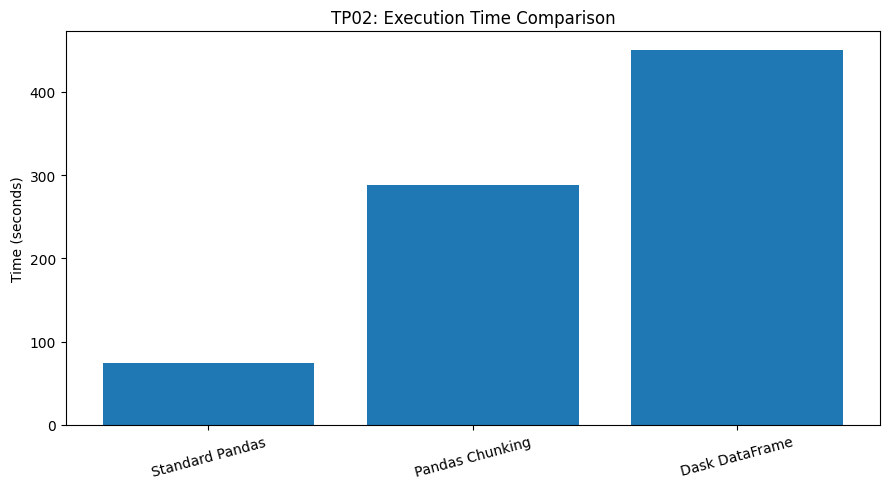

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    benchmark["Method"],
    benchmark["Execution Time (seconds)"]
)

plt.title("TP02: Execution Time Comparison")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

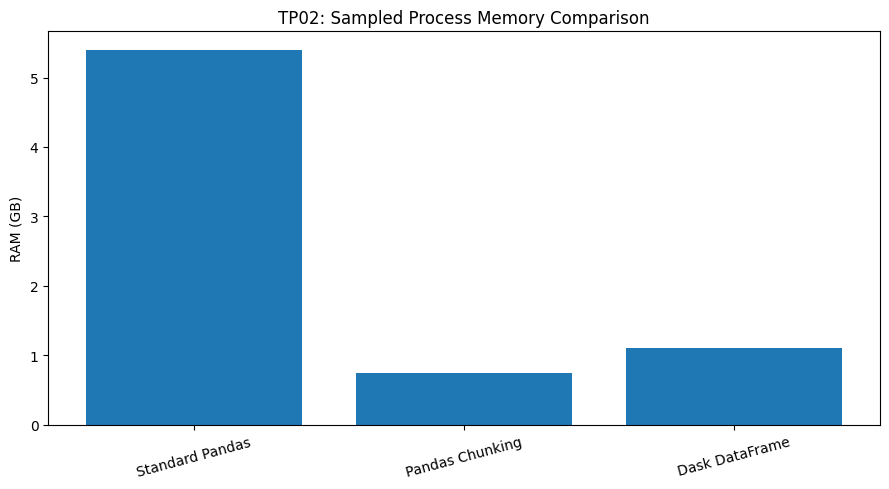

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    benchmark["Method"],
    benchmark["Peak Sampled RAM (GB)"]
)

plt.title("TP02: Sampled Process Memory Comparison")
plt.ylabel("RAM (GB)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
RESULTS_PATH = "/content/big_data/tp02_benchmark_results.csv"

benchmark.to_csv(RESULTS_PATH, index=False)

print("Benchmark saved to:", RESULTS_PATH)

Benchmark saved to: /content/big_data/tp02_benchmark_results.csv
